In [1]:
#Data Manipulation
import pandas as pd
import numpy as np

#Regular expression for text cleaning
import re

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Tensorflow / Keras for the LSTM
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

#Evaluating the classification model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
#For analyzing word frequencies
from collections import Counter

#Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

### Load Dataset

In [3]:
df = pd.read_csv("tweet_emotions.csv")

In [4]:
df.head()

,tweet_id,sentiment,content
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will."


### EDA

In [5]:
#Dataset shape
#Returns 40000 rows and 3 columns
df.shape

(40000, 3)

In [6]:
#Get the columns of the dataset
print(df.columns)

Index(['tweet_id', 'sentiment', 'content'], dtype='object')


#### 1. Dataset Information

In [7]:
#Display information about data types and missing values
#We get the column names, data types, memory usage etc.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   tweet_id   40000 non-null  int64 
 1   sentiment  40000 non-null  object
 2   content    40000 non-null  object
dtypes: int64(1), object(2)
memory usage: 937.6+ KB


#### 2. Statistical Summary

In [8]:
df.describe(include = "all")

,tweet_id,sentiment,content
count,4.000000e+04,40000,40000
unique,NaN,13,39827
top,NaN,neutral,I just received a mothers day card from my lovely daughter wishing my a happy mothers day http://tr.im/kWK9
freq,NaN,8638,14
mean,1.845184e+09,NaN,NaN
std,1.188579e+08,NaN,NaN
min,1.693956e+09,NaN,NaN
25%,1.751431e+09,NaN,NaN
50%,1.855443e+09,NaN,NaN
75%,1.962781e+09,NaN,NaN


### Examine the Comments

In [9]:
#Display 10 random tweets
#Are they genuine tweets
#Are there usernames, emojis, short tweets etc
df.sample(10, random_state = 42)

,tweet_id,sentiment,content
32823,1752414968,neutral,Good Morning
16298,1965295852,empty,"I just put my computer up on craigslist. I've had the same case, monitor, and speakers for over 5 years."
28505,1696219218,love,in ten minutes shopping demi lovato-back around demi lovato-behind enemy lines have you all seen the titanic 2 trailer? its really good!
6689,1961416554,neutral,From twitterberry moved to ubertwitter - suffered from BB cache errors
26893,1695580473,sadness,@thriftymom TEAR*
36572,1753331093,happiness,Ps... I got Ben Button today... completes my Best Picture noms....got all 5 now. It was a GREAT year!!
12335,1963544918,worry,"Just fell asleep for 2 &amp; 1/2 hours so missed both chances for first-look Hollyoaks, ugh"
29591,1751287108,happiness,"@VanetaRogers Thank ye, Vaneta. Much appreciated"
18948,1966120040,sadness,@donttreeriddle Oh noes!! Melted ice cream = do not want.
31067,1751819700,relief,@orphanth i just had pasta from pizzahut.


### Check the Target Variable

In [10]:
#Check number of classes
number_of_classes = df['sentiment'].nunique()
print(f"Number of sentiment classes: {number_of_classes}")

Number of sentiment classes: 13


In [11]:
#Print the number of unique classes
sentiment_classes = df['sentiment'].unique()
print(sentiment_classes)

['empty' 'sadness' 'enthusiasm' 'neutral' 'worry' 'surprise' 'love' 'fun'
 'hate' 'happiness' 'boredom' 'relief' 'anger']


### Class Distribution for Sentiment

In [12]:
#It is very important to discuss this in the report
class_count = df['sentiment'].value_counts()
print(class_count)

sentiment
neutral       8638
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
empty          827
enthusiasm     759
boredom        179
anger          110
Name: count, dtype: int64


There is imbalance in the classes. That is why we will not evaluate accuracy only but also check precision, recall, F1-score, macronF1 and confusion matrix

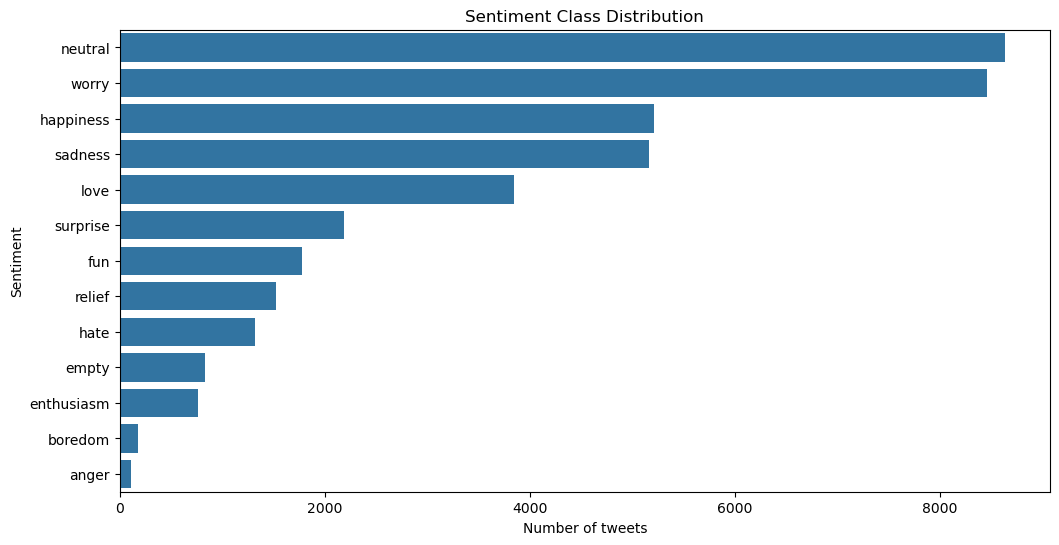

In [13]:
plt.figure(figsize = (12, 6))

sns.countplot(
    data=df, 
    y="sentiment", 
    order=df["sentiment"].value_counts().index)
plt.title("Sentiment Class Distribution")
plt.xlabel("Number of tweets")
plt.ylabel("Sentiment")
plt.show()

### Check Missing Values

In [14]:
print(df.isnull().sum())

tweet_id     0
sentiment    0
content      0
dtype: int64


### Check for duplicates

In [15]:
#Count the number of duplicate records

duplicate_count = df.duplicated().sum()
print(f"Number of duplicates {duplicate_count}")

Number of duplicates 0


In [16]:
#Check for duplicates in the content column only
text_duplicate = df[df["content"].duplicated()]
print(f"No of duplicated comments: {len(text_duplicate)}")

No of duplicated comments: 173


The occurence of duplicate contents with different sentiments can cause confusion

In [17]:
print(text_duplicate)

         tweet_id  sentiment                                        content
366    1957048870      worry             I feel so deflated. No more doggy.
521    1957088574      worry          Somebody please save the polar bears!
1026   1957198430    neutral                                    I'm at work
3684   1958103183    sadness      @dublins98dave me too! I am down 400 euro
4363   1960336689      worry        is upset, I left my phone at home again
...           ...        ...                                            ...
39859  1753886681       love                              Happy Mothers Day
39898  1753902524       love                             happy mothers day!
39913  1753902827  happiness                            happy mother's day!
39915  1753903008       love                    happy mother's day everyone
39945  1753903727       love  Happy Mother's Day to all the moms out there!

[173 rows x 3 columns]


In [18]:
#Remove duplicates based on content column only
df = df.drop_duplicates(subset = ['content'], keep = 'first')

In [19]:
print(df.shape)

(39827, 3)


### Check empty tweets

In [20]:
# Count tweets that contain an empty string
empty_tweets = (
    df["content"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Empty tweets:", empty_tweets)

Empty tweets: 0


### Text Length Features

Character count and word count helps to determine data quality. 

1. We can detect empty or near empty records (shorter comments)
2. We can identify outliers (longer comments)

#### 1. Character Count

In [21]:
df["char_count"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .apply(len)
)

#### 2. Word Count

In [22]:
df["word_count"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .apply(lambda x: len(x.split()))
)

In [23]:
df.head()

,tweet_id,sentiment,content,char_count,word_count
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[,92,18
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...,60,10
2,1956967696,sadness,Funeral ceremony...gloomy friday...,35,3
3,1956967789,enthusiasm,wants to hang out with friends SOON!,36,7
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will.",86,15


In [24]:
df[['char_count', 'word_count']].describe()

,char_count,word_count
count,39827.000000,39827.000000
mean,73.530821,13.242599
std,36.490448,6.962728
min,1.000000,1.000000
25%,43.000000,7.000000
50%,69.000000,12.000000
75%,103.000000,19.000000
max,167.000000,34.000000


#### 3. Plot word count distribution

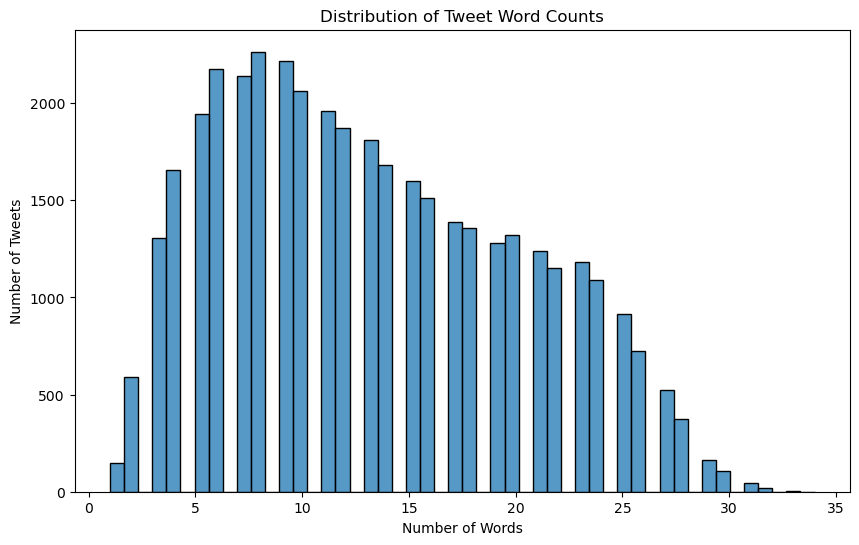

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Tweet Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tweets")

plt.show()

#### 4. Examine unusually short tweets

This lets us determine whether there are tweets containing almost no useful linguistic information

In [26]:
df.nsmallest(
    20,
    "word_count"
)[["sentiment", "content", "word_count"]]

,sentiment,content,word_count
98,neutral,PrinceCharming,1
340,empty,0,1
659,neutral,@Joshuah_Pearson,1
664,neutral,@emlevins,1
1538,neutral,Hangover,1
1539,sadness,roughnight,1
1789,neutral,food...food...FOOD!,1
2206,neutral,nothing,1
2247,neutral,assignments!,1
2311,neutral,backache,1


In [27]:
df[df['word_count'] < 3].head()

,tweet_id,sentiment,content,char_count,word_count
16,1956971170,love,@annarosekerr agreed,20,2
98,1956989561,neutral,PrinceCharming,14,1
124,1956996673,hate,@britblackbird youstinkatrespondingtotexts!,44,2
137,1957000077,neutral,miss 16'th,10,2
340,1957042734,empty,0,1,1


#### 5. Examine unusually long tweets

In [28]:
#if we have unneccessarily long tweets, this signifies outliers
df.nlargest(
    20,
    "word_count"
)[["sentiment", "content", "word_count"]]

,sentiment,content,word_count
28293,worry,hahas . dam tried . just nw got exam . don know how much i will get . . but i having fun today . with my pri sch friends until 5plus . =D,34
9818,neutral,"AK, flop comes 2K6 I bet 15 get raised to 25 I call, turn is A, we check, river rag, then I check and he bets 15, I raise 15 he calls, 22",33
17027,worry,@oxEmalieexo: Lol it went okay! As far as I can tell . But then I had to do a test today for geo and I was all zoned out and got like 65%,33
1711,hate,This is exactly y I hate driving thru dandy - sittin at lights next to a car of asians who r callin out to me &amp; 1 held up a knife scum!,32
2627,sadness,"How I wish I get at least 2 days-off in a row. 1 day off is not enough to rest. 3 days on, 1 day off, 4 days on, 1 day off...Ugh!!!",32
5459,sadness,My car is in the car hospital for the nxt 7 days I gotta go pick up a loaner car b4 6! Bein without wheels 4 7day will set me back heavy!,32
7908,love,Ahhh I am sooo happy Ashley Tisdale is in Germany but I am not in Oberhausen... But i will show it in the TV at 8 o' clock yeah I love it,32
12868,love,@MadisonApril lol haha fresh to death lol ha ha I love and miss u 2 id almost given ï¿½ on u cuz u nvr respond 2me but u did today! Luv u2,32
13092,sadness,Is Home Alone Yet Again; Mam And Dad Rather Go To The Club Than Stay In With Me Or Take Me Out; Yes I Think That Proves How Loved I Am !,32
13435,neutral,@chrisettefan yep. gotta go man! i'll ttyl . . . eventually . . . sometime . . . in the future . . . hopefully . . . soon. ~ ~ ~,32


#### 6. Compare text length by emotion

It helps us to determine if the tweet length differ between emotional classes

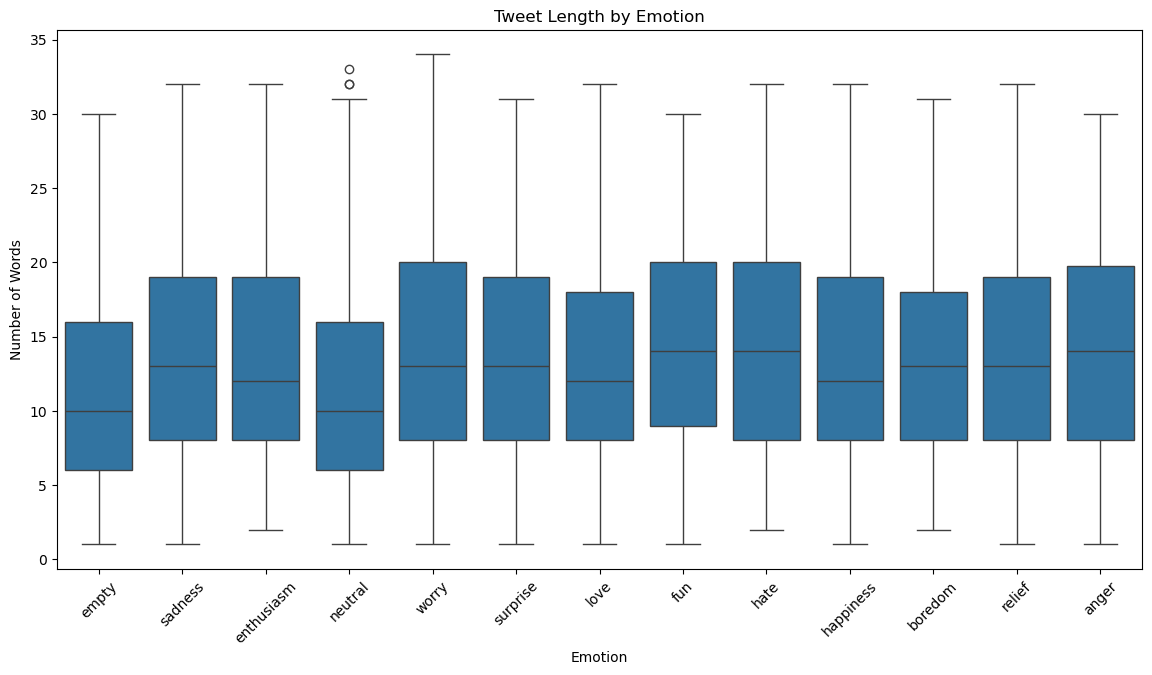

In [29]:
#the graph did not show much difference in tweet lengths
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.xticks(rotation=45)

plt.title("Tweet Length by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Words")

plt.show()

### Clean the Text (Content)

In [30]:
def clean_tweet(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Replace URLs with a special token
    text = re.sub(
        r"http\S+|www\S+",
        " <URL> ",
        text
    )

    # Replace Twitter usernames with a special token
    text = re.sub(
        r"@\w+",
        " <USER> ",
        text
    )

    # Remove unwanted HTML or special characters
    text = re.sub(r"<.*?>", " ", text)

    # Remove extra whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove leading and trailing spaces
    text = text.strip()
    

    return text

In [31]:
df["clean_text"] = df["content"].apply(clean_tweet)

#### 3. Compare the Original and Clean Tweet

In [32]:
comparison = df[
    ["content", "clean_text"]
].sample(
    10,
    random_state=42
)

comparison

,content,clean_text
37761,the sun is shinning! im off out!!,the sun is shinning! im off out!!
1903,wow i must have been tired. i fell asleep @ exactly the start of the 10pm news &amp; now up as if its 8am.,wow i must have been tired. i fell asleep @ exactly the start of the 10pm news &amp; now up as if its 8am.
16633,@knobzie their loss,their loss
27370,@Mickey_X sorry about that.,sorry about that.
21139,@tracymacy My pleasure,my pleasure
34688,Exhausted to the tee.. So i'm knocking out! Nighty night tweety birds,exhausted to the tee.. so i'm knocking out! nighty night tweety birds
6250,"@PochaccoYoly well, I took it in early '00, graduated in '01. we were the final stage guinea pigs it seriously is a waste of time.","well, i took it in early '00, graduated in '01. we were the final stage guinea pigs it seriously is a waste of time."
33181,X-men movie was pretty good. Kinda predictable @ points but good action sequences,x-men movie was pretty good. kinda predictable @ points but good action sequences
27193,Less rain more sunshine,less rain more sunshine
24904,"Jamie @ Sean Cody, up for some angry sex?: Jamie @ Sean Cody, I wouldn't piss this one off Hey there Guys, Do.. http://tinyurl.com/ddyyd6","jamie @ sean cody, up for some angry sex?: jamie @ sean cody, i wouldn't piss this one off hey there guys, do.."


### Analyze the Vocabulary (Word Count)

This only helps us to understand teh vocabulary of dataset. We are not removing common words because word order and context are important when dealing with LSTM

In [33]:
# Combine all cleaned tweets
all_text = " ".join(df["clean_text"])

# Split into words
words = all_text.split()

# Count the frequency of every word
word_counts = Counter(words)

# Display the 30 most common words
print(word_counts.most_common(30))

[('i', 18865), ('to', 14232), ('the', 12823), ('a', 9701), ('my', 7939), ('and', 7237), ('you', 6086), ('is', 5581), ('in', 5248), ('for', 5235), ('it', 4804), ('of', 4473), ('on', 4001), ('have', 3713), ('so', 3540), ('that', 3333), ('me', 3270), ('but', 3192), ('just', 3107), ("i'm", 3102), ('with', 2912), ('be', 2837), ('at', 2673), ('was', 2601), ('not', 2500), ('day', 2137), ('this', 2130), ('all', 2077), ('get', 1985), ('good', 1937)]


### Examine Twitter Specific Features

In [34]:
#Mentions
df["mentions"] = (
    df["content"]
    .astype(str)
    .str.count(r"@\w+")
)

#URLs
df["urls"] = (
    df["content"]
    .astype(str)
    .str.count(
        r"http\S+|www\S+"
    )
)

#Hash Tags
df["hashtags"] = (
    df["content"]
    .astype(str)
    .str.count(r"#\w+")
)

#Exclamation marks
df["exclamation_marks"] = (
    df["content"]
    .astype(str)
    .str.count("!")
)

#Question marks
df["question_marks"] = (
    df["content"]
    .astype(str)
    .str.count(r"\?")
)

In [35]:
#Examine the features
df[
    [
        "mentions",
        "urls",
        "hashtags",
        "exclamation_marks",
        "question_marks"
    ]
].describe()

,mentions,urls,hashtags,exclamation_marks,question_marks
count,39827.000000,39827.000000,39827.000000,39827.000000,39827.000000
mean,0.501946,0.051322,0.023100,0.550506,0.168855
std,0.570553,0.226052,0.183617,1.345531,1.224237
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,1.000000,0.000000
max,10.000000,4.000000,9.000000,76.000000,98.000000


### Prepare the Target Variable

In [36]:
#Convert Emotions to Numerical Values
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["sentiment"]
)

In [37]:
#View the Mapping
for number, emotion in enumerate(
    label_encoder.classes_
):
    print(number, "=", emotion)

0 = anger
1 = boredom
2 = empty
3 = enthusiasm
4 = fun
5 = happiness
6 = hate
7 = love
8 = neutral
9 = relief
10 = sadness
11 = surprise
12 = worry


### Select X and Y

In [38]:
x = df["clean_text"]

y = df["label"]

### Split the Data

Stratifying preserves the class distribution

In [39]:
#Split into train and test
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [40]:
#Split train into train and validation
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

### Tokenisation

Tokenisation converts the text into numbers. The tokenizer will still index all the unque words it encounters in the corpus, but will only use the num_words as word ID

In [41]:
max_words = 20000

#num_words define the max num of words to retain in the vocab
#Keeps 20000 most frequent words
tokenizer = Tokenizer(num_words = max_words, oov_token = "<OOV>")
#Fit on the training data only
#This prevents information from val and test from leaking
tokenizer.fit_on_texts(x_train)

### Examine Vocabulary Size

In [42]:
word_index = tokenizer.word_index

print(f"Vocab size: {len(word_index)}")

Vocab size: 22331


### Covert Text to Sequence

In [43]:
x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq = tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

### Determine Appropriate Sequence Length

In [44]:
sequence_lengths = [len(sequence) for sequence in x_train_seq]

print(pd.Series(sequence_lengths).describe())

count    22302.000000
mean        12.820330
std          7.064873
min          0.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         36.000000
dtype: float64


### Visualize the Distribution

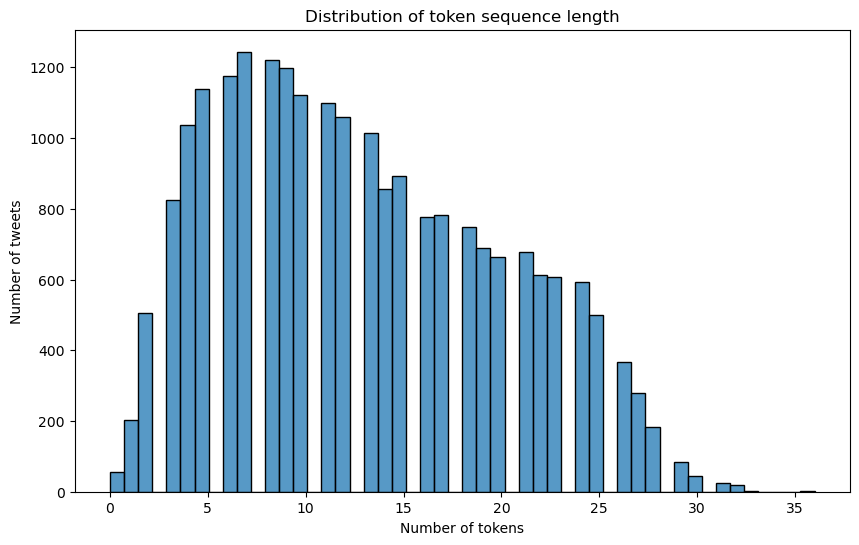

In [45]:
plt.figure(figsize = (10, 6))
sns.histplot(sequence_lengths, bins=50)
plt.title("Distribution of token sequence length")
plt.ylabel("Number of tweets")
plt.xlabel("Number of tokens")
plt.show()

### Padding

In [46]:
max_sequence = 50

x_train = pad_sequences(
    x_train_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

x_val = pad_sequences(
    x_val_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

x_test = pad_sequences(
    x_test_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

### Check input shape

In [47]:
print(f"training shape {x_train.shape}")
print(f"validation shape {x_val.shape}")
print(f"test shape {x_test.shape}")

training shape (22302, 50)
validation shape (5576, 50)
test shape (11949, 50)


### Build Initial LSTM 

In [99]:
model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
model.add(LSTM(64))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [100]:
#Display the model architecture
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [101]:
#What is the purpose of compile
#Compile
#We use sparse_categorical_cross entropy cos we are dealing with ,multiclass
model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

With softmax the output layer produces an output of probabilities for each of the classes. These probabilities sum up to 1. THe class with the largest probability becomes the prediction. 

### Train the Initial Model

In [102]:
### Explain the code
from tensorflow.keras.callbacks import EarlyStopping

#Because we have an imbalanced class, 
#It is recommended using early stopping

early_stopping = EarlyStopping(
    monitor = "val_loss", 
    patience = 2, 
    restore_best_weights = True)

In [104]:
#train
history = model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64, 
    callbacks = [early_stopping]
)

Epoch 1/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.2104 - loss: 2.1980 - val_accuracy: 0.2159 - val_loss: 2.1476
Epoch 2/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.2131 - loss: 2.1665 - val_accuracy: 0.2159 - val_loss: 2.1457
Epoch 3/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.2120 - loss: 2.1604 - val_accuracy: 0.2159 - val_loss: 2.1461
Epoch 4/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.2119 - loss: 2.1579 - val_accuracy: 0.2159 - val_loss: 2.1457
Epoch 5/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.2154 - loss: 2.1547 - val_accuracy: 0.2118 - val_loss: 2.1455
Epoch 6/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.2193 - loss: 2.1542 - val_accuracy: 0.2613 - val_loss: 2.1383
Epoch 7/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.2586 - loss: 2.1281 - val_accuracy: 0.2701 - val_loss: 2.1039
Epoch 8/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.2843 - loss: 2.0703 - 

1. history.history is a dictionary with training and validation metrics per epoch
2. history.epoch is a list of epoch numbers
3. history.params contains configuration parameters used for training. 

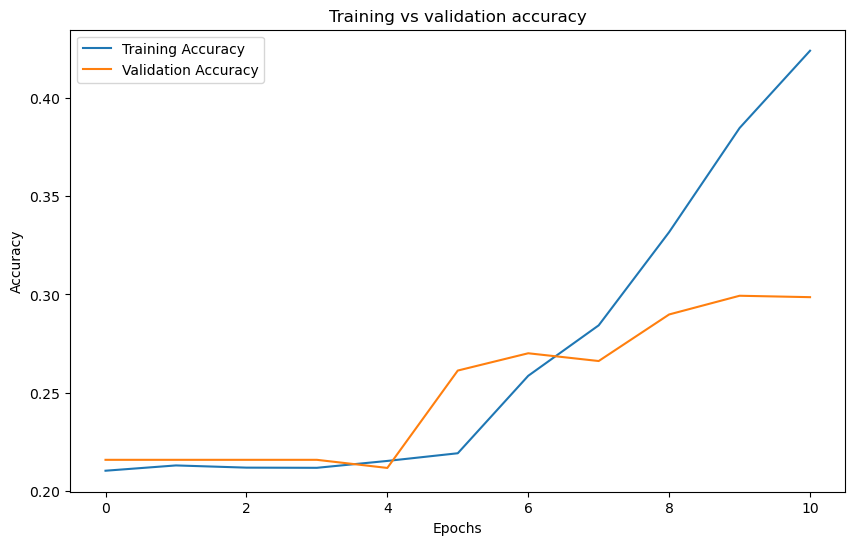

In [105]:
#Visualize the training values
plt.figure(figsize = (10, 6))
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.title("Training vs validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


#NOTE
#If training and val accuracy are both increasing, 
#the model is generalizing and learning
#If training is increasing and validation accuracy stops improving
#the model may be overfitting

#If there is overfitting at this point, how do we address it?

We observe that the training continues to improve in its accuracy while the validation stopped improving. This is a sign of overfitting. When both were increasing together, the LSTM was learning patterns that generalize beyond the training data. When the validation stopped improving, the model was beginning to memorise characteristics of the training tweets rather than learning general patterns that distinguish emotion classes.

*** Interventions ***

1. Introduce early stopping (which we did already)
2. Introduce drop out (we did already) but we can adjust it to 0.5


Do not confuse overfitting problem and class imbalance problem. Class imbalance is a data distribution problem while overfitting is a generalization problem. 

### Plot Loss

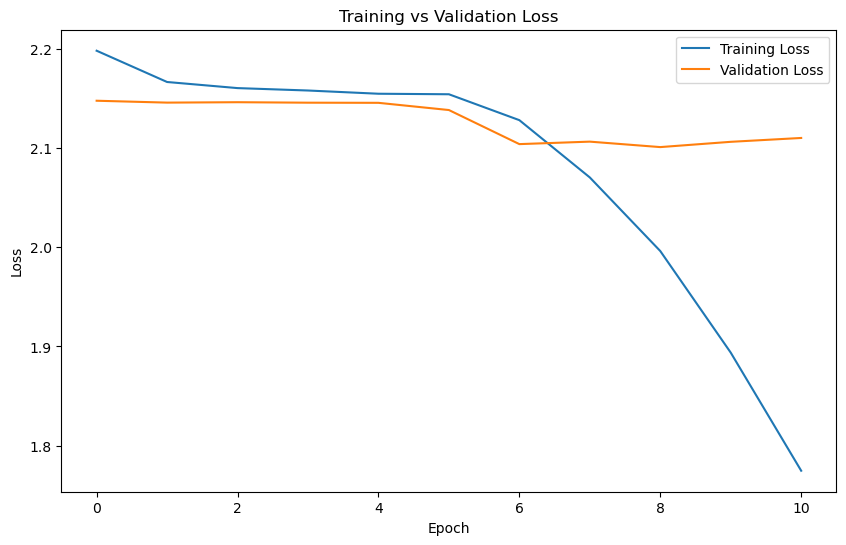

In [106]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

#NOTE
#The two are expected to continue to reduce
#If train increase and val decrease, this indicates overfitting

#If there is overfitting, what do we do?

### Evaluate on the Test Set

In [107]:
#This gives the overall accuracy

#NOTE
#Verbose controls the amount of information printed to the console
#Verbose = 0 (no output)
#verbose = 1 progress bar with loss/accuracy
#verbose = 2 One line per batch

#NOTE
#model.evaluate() automatically performs the predict
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose = 0)

print("Test Loss: ", test_loss)
print("Test Accuracy", test_accuracy)

#We cannot stop here because of imbalanced class

Test Loss:  2.103219509124756
Test Accuracy 0.287555456161499


### Generate Prediction

In [108]:
#Generate probability predictions
#NOTE
#Softmax generates probabilities for each emotion
y_probability = model.predict(x_test)

#Select the class with the hightest probability
y_pred = np.argmax(y_probability, axis = 1)

374/374 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


### Accuracy

Accuracy answers what proportion of tweets were classified correctly

In [109]:
#How is this accuracy different from the previous evaluation?

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)

Accuracy:  0.2875554439702067


### Precision

Precision answers the question, of all the times the model predicted positive, how many were actually positive? (True +ve / (True +ve + false +ve))

Macro precision calculate precision independently for every class and then give every class equal weight

In [110]:
precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro Precision:", precision)

Macro Precision: 0.08880398743330538


### Recall

Recall answers the questions: of all the actual positives, how many did I correctly predict? (TP / (TP + FN))All tweets belonging to an emotion, how many tweets were correctly predicted

In [111]:
recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro Recall:", recall)

Macro Recall: 0.12292037348164256


### Macro F1

F1 score computes the harmonic mean of precision and recall. It combines both metrics into a single number that balances the two. The F1 score answers the question: how well does my model balances not missing positives (recall) and not raising false alarms (precision). 

Macro F1 is the unweighted average of the F1 scores of each class = F1_emotion1 + F1_emotion2...F1_emotionN / N. Here, every class contributes equally, regardless of how many samples it has.

Because of the imbalanced dataset, the Macro F1 is like the most important metrics because it gives all classes equal importance

In [112]:
f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro F1:", f1)

Macro F1: 0.09821205909196004


### Classification Report 

In [113]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        33
     boredom       0.00      0.00      0.00        54
       empty       0.00      0.00      0.00       247
  enthusiasm       0.00      0.00      0.00       227
         fun       0.00      0.00      0.00       532
   happiness       0.25      0.14      0.17      1555
        hate       0.00      0.00      0.00       397
        love       0.32      0.36      0.34      1136
     neutral       0.34      0.56      0.42      2580
      relief       0.00      0.00      0.00       457
     sadness       0.00      0.00      0.00      1546
    surprise       0.00      0.00      0.00       654
       worry       0.25      0.54      0.34      2531

    accuracy                           0.29     11949
   macro avg       0.09      0.12      0.10     11949
weighted avg       0.19      0.29      0.22     11949



### Confusion Matrix

In [114]:
cm = confusion_matrix(
    y_test,
    y_pred
)

Let's compute the confusion matrix. This is how we interpret the matrix. if the model frequently confuses fun and happiness OR boredom and anger, it makes intuitive sense because they are likely sharing the same vocabulary. But if it confuses happiness and sadness,it makes no sense

### Identify the Weakest Emotions

This allows us to identify which emotions are hardest for the LSTM.

In [116]:
report = classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df

,precision,recall,f1-score,support
anger,0.000000,0.000000,0.000000,33.000000
boredom,0.000000,0.000000,0.000000,54.000000
empty,0.000000,0.000000,0.000000,247.000000
enthusiasm,0.000000,0.000000,0.000000,227.000000
fun,0.000000,0.000000,0.000000,532.000000
happiness,0.245921,0.135691,0.174886,1555.000000
hate,0.000000,0.000000,0.000000,397.000000
love,0.324881,0.360915,0.341952,1136.000000
neutral,0.335733,0.560465,0.419922,2580.000000
relief,0.000000,0.000000,0.000000,457.000000


In [117]:
report_df.sort_values(
    by="f1-score"
)

,precision,recall,f1-score,support
anger,0.000000,0.000000,0.000000,33.000000
boredom,0.000000,0.000000,0.000000,54.000000
empty,0.000000,0.000000,0.000000,247.000000
enthusiasm,0.000000,0.000000,0.000000,227.000000
fun,0.000000,0.000000,0.000000,532.000000
hate,0.000000,0.000000,0.000000,397.000000
sadness,0.000000,0.000000,0.000000,1546.000000
relief,0.000000,0.000000,0.000000,457.000000
surprise,0.000000,0.000000,0.000000,654.000000
macro avg,0.088804,0.122920,0.098212,11949.000000


### Important finding: Class Imbalance

Due to the class imbalance, it is possible that the initial LSTM will perform better on large classes than small classes

### Improve the model using class weights

The rare classes receive larger weigh while common classes receive lesser weight

In [118]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(
    zip(
        np.unique(y_train),
        class_weights_array
    )
)

print(class_weights)

{np.int64(0): np.float64(27.669975186104217), np.int64(1): np.float64(17.155384615384616), np.int64(2): np.float64(3.72943143812709), np.int64(3): np.float64(4.036561085972851), np.int64(4): np.float64(1.7258938244853739), np.int64(5): np.float64(0.5909536553697766), np.int64(6): np.float64(2.3182952182952183), np.int64(7): np.float64(0.8095981413584057), np.int64(8): np.float64(0.35636444984180754), np.int64(9): np.float64(2.013542795232936), np.int64(10): np.float64(0.5944346713577483), np.int64(11): np.float64(1.403877628100214), np.int64(12): np.float64(0.3630769230769231)}


### Retrain the model with class weights

In [119]:
model_weighted = Sequential()

model_weighted.add(
    Embedding(
        input_dim=max_words,
        output_dim=128
    )
)

model_weighted.add(
    LSTM(128)
)

model_weighted.add(
    Dropout(0.5)
)

model_weighted.add(
    Dense(
        len(label_encoder.classes_),
        activation="softmax"
    )
)

In [120]:
#Compile
model_weighted.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [121]:
#Train
history_weighted = model_weighted.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
    #callbacks=[early_stopping]
)

Epoch 1/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 25s 65ms/step - accuracy: 0.0500 - loss: 2.5703 - val_accuracy: 0.0547 - val_loss: 2.5628
Epoch 2/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.0437 - loss: 2.5669 - val_accuracy: 0.0045 - val_loss: 2.5758
Epoch 3/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 23s 66ms/step - accuracy: 0.0592 - loss: 2.5686 - val_accuracy: 0.0326 - val_loss: 2.5713
Epoch 4/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.0551 - loss: 2.5691 - val_accuracy: 0.0951 - val_loss: 2.5578
Epoch 5/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.0549 - loss: 2.5670 - val_accuracy: 0.0332 - val_loss: 2.5652
Epoch 6/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.0400 - loss: 2.5683 - val_accuracy: 0.0190 - val_loss: 2.5581
Epoch 7/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.0648 - loss: 2.5676 - val_accuracy: 0.0447 - val_loss: 2.5610
Epoch 8/10
349/349 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.0518 - loss: 2.5669 - 

In [122]:
#Evaluate the improved model

weighted_probability = model_weighted.predict(
    x_test
)

weighted_prediction = np.argmax(
    weighted_probability,
    axis=1
)

374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step


### Calculate Metrics

In [123]:
weighted_accuracy = accuracy_score(
    y_test,
    weighted_prediction
)

weighted_precision = precision_score(
    y_test,
    weighted_prediction,
    average="macro",
    zero_division=0
)

weighted_recall = recall_score(
    y_test,
    weighted_prediction,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    weighted_prediction,
    average="macro",
    zero_division=0
)

print("Improved Accuracy :", weighted_accuracy)
print("Improved Precision:", weighted_precision)
print("Improved Recall   :", weighted_recall)
print("Improved F1       :", weighted_f1)

Improved Accuracy : 0.12938321198426647
Improved Precision: 0.009952554768020499
Improved Recall   : 0.07692307692307693
Improved F1       : 0.017624761307606804


### Compare the models

In [124]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],

    "Initial LSTM": [
        accuracy,
        precision,
        recall,
        f1
    ],

    "Weighted LSTM": [
        weighted_accuracy,
        weighted_precision,
        weighted_recall,
        weighted_f1
    ]
})

comparison

,Metric,Initial LSTM,Weighted LSTM
0,Accuracy,0.287555,0.129383
1,Macro Precision,0.088804,0.009953
2,Macro Recall,0.122920,0.076923
3,Macro F1,0.098212,0.017625


### Improved Confusion Matrix

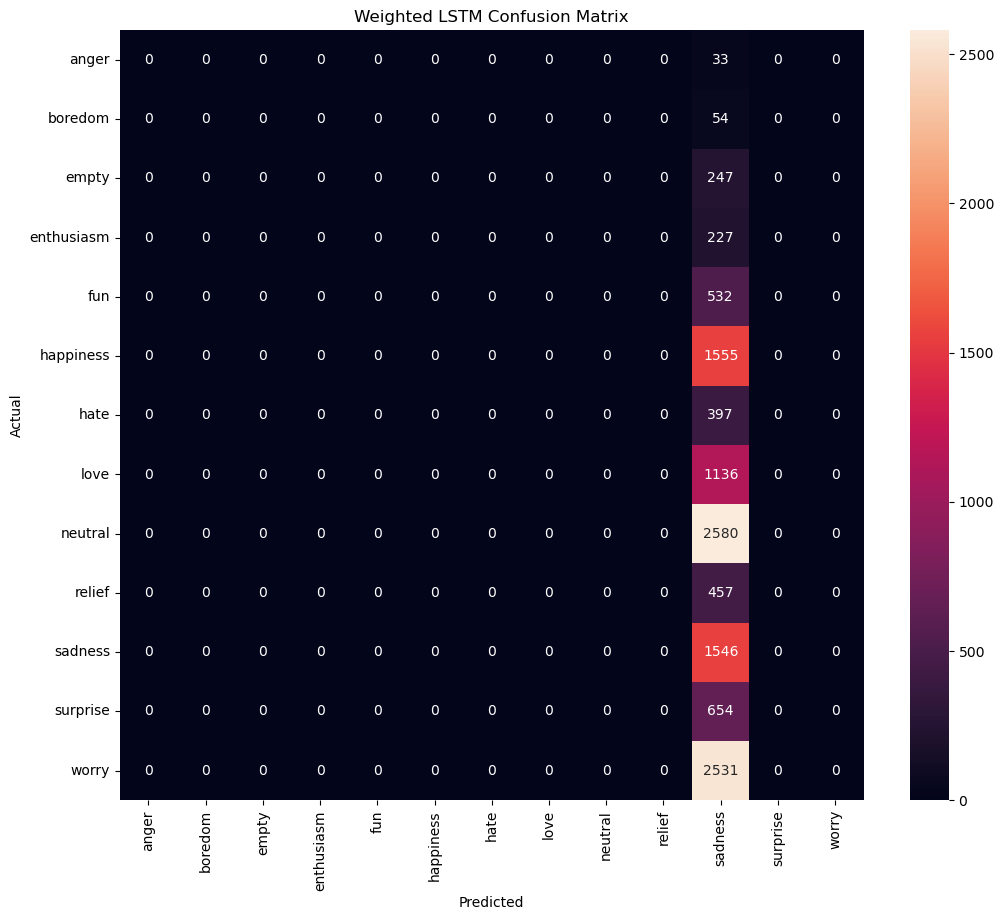

In [125]:
cm_weighted = confusion_matrix(
    y_test,
    weighted_prediction
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_weighted,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Weighted LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## NOTE

1. Consider the use of p-value for feature selection

In [127]:
for class_id, weight in class_weights.items():
    print(
        class_id,
        label_encoder.classes_[class_id],
        weight
    )

0 anger 27.669975186104217
1 boredom 17.155384615384616
2 empty 3.72943143812709
3 enthusiasm 4.036561085972851
4 fun 1.7258938244853739
5 happiness 0.5909536553697766
6 hate 2.3182952182952183
7 love 0.8095981413584057
8 neutral 0.35636444984180754
9 relief 2.013542795232936
10 sadness 0.5944346713577483
11 surprise 1.403877628100214
12 worry 0.3630769230769231


### GRU

In [47]:
from tensorflow.keras.layers import GRU

In [48]:
model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
model.add(GRU(128))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [49]:
#What is the purpose of compile
#Compile
#We use sparse_categorical_cross entropy cos we are dealing with ,multiclass
model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [50]:
#train
history = model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64 
    #callbacks = [early_stopping]
)

Epoch 1/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 22s 56ms/step - accuracy: 0.2088 - loss: 2.1827 - val_accuracy: 0.2159 - val_loss: 2.1467
Epoch 2/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.2181 - loss: 2.1601 - val_accuracy: 0.2183 - val_loss: 2.1411
Epoch 3/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.2854 - loss: 2.0406 - val_accuracy: 0.3330 - val_loss: 1.9503
Epoch 4/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.3877 - loss: 1.7968 - val_accuracy: 0.3320 - val_loss: 1.9889
Epoch 5/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.4829 - loss: 1.5496 - val_accuracy: 0.3171 - val_loss: 2.0923
Epoch 6/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.5726 - loss: 1.2986 - val_accuracy: 0.2923 - val_loss: 2.2874
Epoch 7/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.6584 - loss: 1.0724 - val_accuracy: 0.2852 - val_loss: 2.5276
Epoch 8/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.7252 - loss: 0.8867 - 

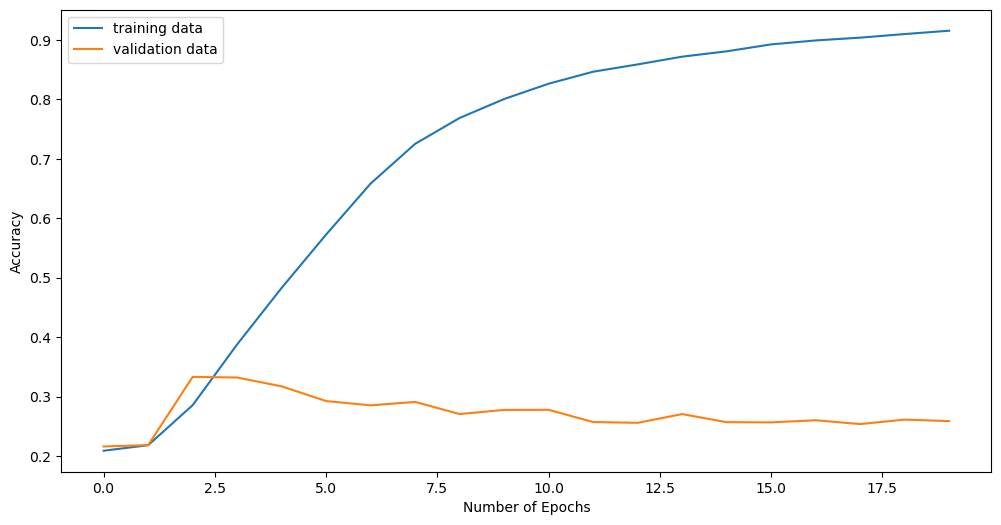

In [51]:
#Plot

plt.figure(figsize = (12, 6))
plt.plot(history.history["accuracy"], label = "training data")
plt.plot(history.history["val_accuracy"], label = "validation data")
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [65]:
gru_model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
gru_model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
gru_model.add(GRU(64))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
gru_model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
gru_model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [66]:
#What is the purpose of compile
#Compile
#We use sparse_categorical_cross entropy cos we are dealing with ,multiclass
gru_model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [63]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = "val_loss", 
    patience = 2, 
    restore_best_weights = True)

In [67]:
#train
gru_history = gru_model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64, 
    callbacks = [early_stopping]
)

Epoch 1/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.2087 - loss: 2.1956 - val_accuracy: 0.2159 - val_loss: 2.1534
Epoch 2/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.2119 - loss: 2.1664 - val_accuracy: 0.2159 - val_loss: 2.1437
Epoch 3/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.2627 - loss: 2.0887 - val_accuracy: 0.3298 - val_loss: 1.9718
Epoch 4/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.3754 - loss: 1.8581 - val_accuracy: 0.3225 - val_loss: 1.9707
Epoch 5/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.4774 - loss: 1.5918 - val_accuracy: 0.3137 - val_loss: 2.1389
Epoch 6/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.5796 - loss: 1.3255 - val_accuracy: 0.2941 - val_loss: 2.3171


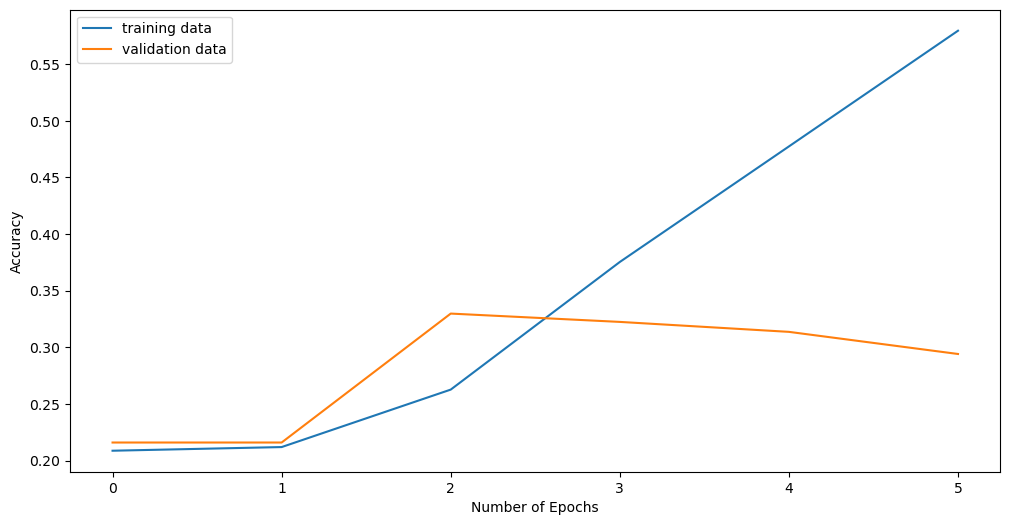

In [68]:
#Plot

plt.figure(figsize = (12, 6))
plt.plot(gru_history.history["accuracy"], label = "training data")
plt.plot(gru_history.history["val_accuracy"], label = "validation data")
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Simple RNN

In [56]:
from tensorflow.keras.layers import SimpleRNN

rnn_model = Sequential([
    Embedding(max_words, 128),
    SimpleRNN(128),
    Dropout(0.6),
    Dense(len(label_encoder.classes_), activation="softmax")
])

In [57]:
rnn_model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [58]:
#train
history = rnn_model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64 
    #callbacks = [early_stopping]
)

Epoch 1/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.2087 - loss: 2.2059 - val_accuracy: 0.2077 - val_loss: 2.1503
Epoch 2/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.2234 - loss: 2.1637 - val_accuracy: 0.2290 - val_loss: 2.1554
Epoch 3/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.2385 - loss: 2.1484 - val_accuracy: 0.2188 - val_loss: 2.1513
Epoch 4/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.2324 - loss: 2.1491 - val_accuracy: 0.2290 - val_loss: 2.1534
Epoch 5/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.2363 - loss: 2.1467 - val_accuracy: 0.2193 - val_loss: 2.1480
Epoch 6/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.2407 - loss: 2.1436 - val_accuracy: 0.2157 - val_loss: 2.1452
Epoch 7/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.2400 - loss: 2.1416 - val_accuracy: 0.2123 - val_loss: 2.1885
Epoch 8/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.2329 - loss: 2.1460 - 